In [1]:
import librosa
import librosa.display
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#load audio files
BASE_PATH = './audio'

deb_path = f"{BASE_PATH}/debussy.wav"
duke_path = f"{BASE_PATH}/duke.wav"
redhot_path = f"{BASE_PATH}/redhot.wav"

deb, _ = librosa.load(deb_path)
duk, _ = librosa.load(duke_path)
red, _ = librosa.load(redhot_path)

In [6]:
# Extract RMS with librosa

FRAME_LENGTH = 1024
HOP_LENGTH = 512

rms_deb = librosa.feature.rms(y=deb, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)[0]
rms_red = librosa.feature.rms(y=duk, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)[0]
rms_duk = librosa.feature.rms(y=red, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)[0]

In [7]:
rms_deb.shape

(1292,)

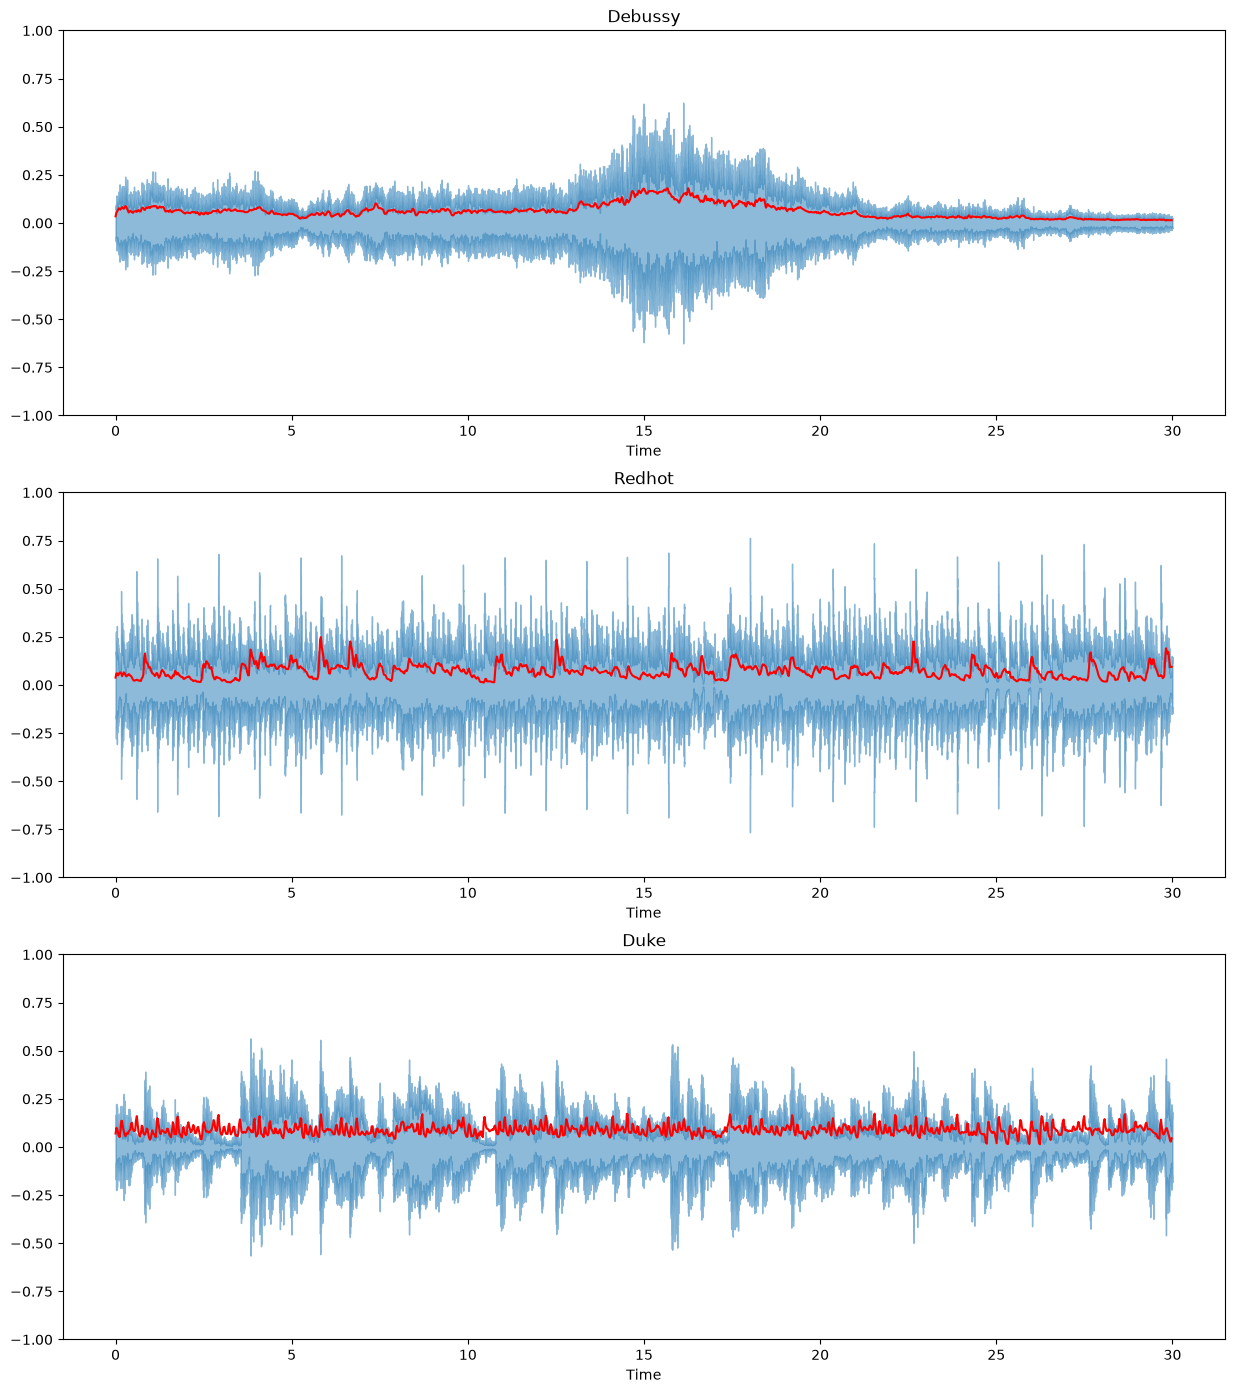

In [8]:
frames = range(0, rms_deb.size)
t = librosa.frames_to_time(frames, hop_length=HOP_LENGTH)

plt.figure(figsize=(15,17))

plt.subplot(3,1,1)
librosa.display.waveshow(deb, alpha=0.5)
plt.plot(t, rms_deb, color='r')
plt.title("Debussy")
plt.ylim(-1, 1)

plt.subplot(3,1,2)
librosa.display.waveshow(red, alpha=0.5)
plt.plot(t, rms_red, color='r')
plt.title("Redhot")
plt.ylim(-1, 1)

plt.subplot(3,1,3)
librosa.display.waveshow(duk, alpha=0.5)
plt.plot(t, rms_duk, color='r')
plt.title("Duke")
plt.ylim(-1, 1)

plt.show()

In [9]:

def rms(signal, frame_length: int, hop_length: int):
    return np.array([np.sqrt( np.sum(signal[i:i+frame_length]**2)/ frame_length ) for i in range(0, signal.size, hop_length)])

In [10]:
rms_deb = rms(deb, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)
duk_deb = rms(duk, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)
red_deb = rms(red, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)

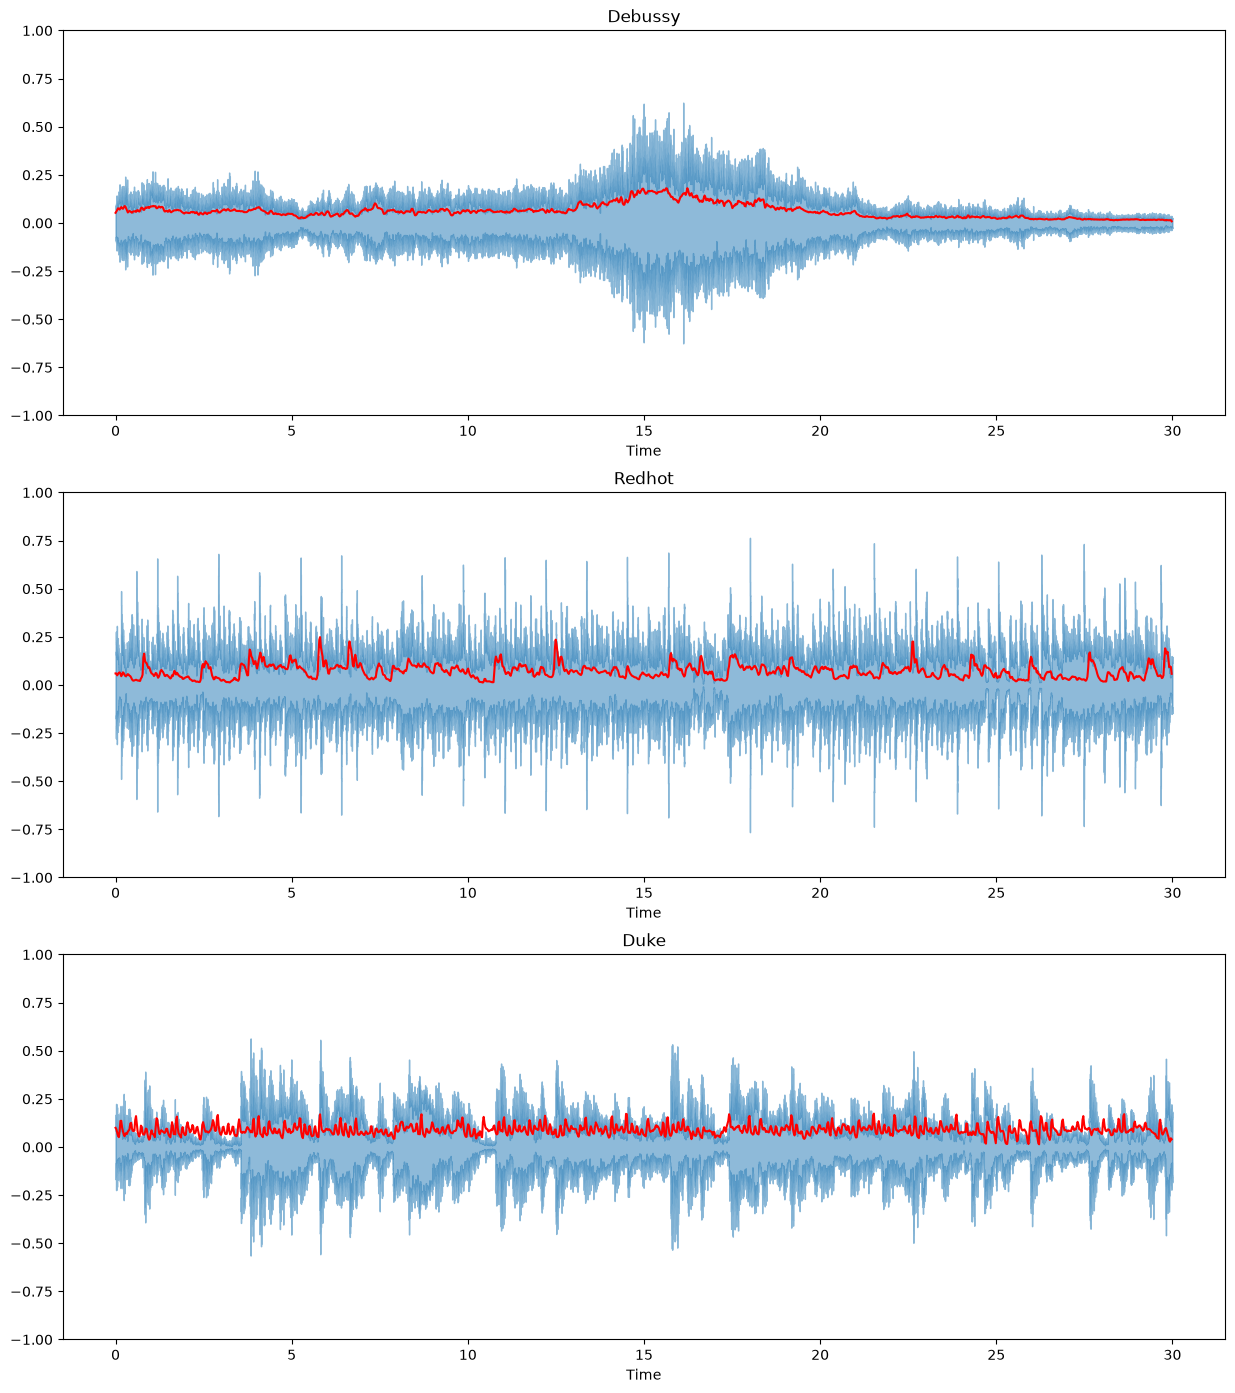

In [11]:
frames = range(0, rms_deb.size)
t = librosa.frames_to_time(frames, hop_length=HOP_LENGTH)

plt.figure(figsize=(15,17))

plt.subplot(3,1,1)
librosa.display.waveshow(deb, alpha=0.5)
plt.plot(t, rms_deb, color='r')
plt.title("Debussy")
plt.ylim(-1, 1)

plt.subplot(3,1,2)
librosa.display.waveshow(red, alpha=0.5)
plt.plot(t, duk_deb, color='r')
plt.title("Redhot")
plt.ylim(-1, 1)

plt.subplot(3,1,3)
librosa.display.waveshow(duk, alpha=0.5)
plt.plot(t, red_deb, color='r')
plt.title("Duke")
plt.ylim(-1, 1)

plt.show()